In [1]:
%pylab inline

Populating the interactive namespace from numpy and matplotlib


In [2]:
from __future__ import division
import matplotlib.pyplot as plt
from deltasigma import *
import numpy as np
from IPython.core.display import Image
import numpy as np, pandas as pd

#from turtle import title
from matplotlib import text

from itertools import zip_longest as izip_longest
from scipy.signal import tf2zpk
from scipy.signal import lfilter


In [3]:
class Table(list):
    def _repr_html_(self):
        html = ["<table>"]
        for row in self:
            html.append("<tr>")
            for col in row:
                try:
                    float(col)
                    html.append("<td>%.6f</td>" % col)
                except(ValueError):
                    html.append("<td><b>%s</b></td>" % col)
            html.append("</tr>")
        html.append("</table>")
        return ''.join(html)

In [4]:
order = 1
osr = 8
nlev = 8
Hinf = 2
form = 'CRFBD'

In [6]:
ntf = synthesizeNTF(order, osr, H_inf=Hinf)            # Optimized zero placement
print ("Synthesized a %d-order NTF, with roots:\n" % order)
print (" Zeros:\t\t\t Poles:")
# for z, p in zip(ntf[0], ntf[1]):
#     print ("(%f, %fj)\t(%f, %fj)" % (np.real(z), np.imag(z), np.real(p), np.imag(p)))
# print ("")

print ("NTF:\n")
print (pretty_lti(ntf))

Synthesized a 1-order NTF, with roots:

 Zeros:			 Poles:
NTF:

 (z - 1) 
---------
    z    


/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_synthesizeNTF1.py:107: UserWarning: Unable to achieve specified Hinf.
Setting all NTF poles to zero.
  warn('Unable to achieve specified Hinf.\n'


/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_plotPZ.py:85: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
  hold_status = plt.ishold()
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_plotPZ.py:90: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
  plt.hold(True)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/__init__.py:913: MatplotlibDeprecationWarning: axes.hold is deprecated. Please remove it from your matplotlibrc and/or style files.
  mplDeprecation)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/rcsetup.py:158: MatplotlibDeprecationWarning: axes.hold is deprecated, will be removed

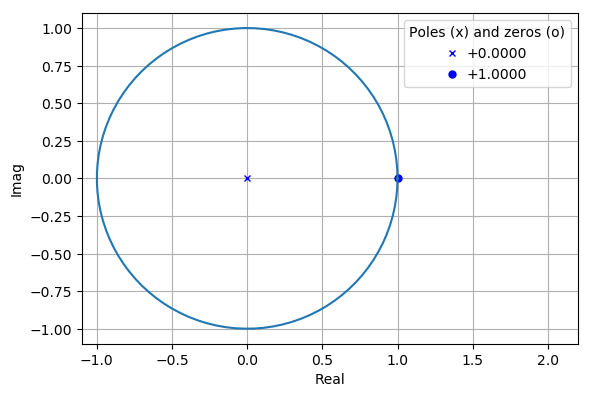

In [7]:
plotPZ(ntf, showlist=True)
a, g, b, c = realizeNTF(ntf, form)

In [ ]:

ABCD = np.array([[1., 1., -1.],
                [1., 0.,  0.]]) 
print (("ABCD Matrix:\n" + str(ABCD)))

ABCD Matrix:
[[ 1. -1.  1.]
 [-1.  1.  0.]]


/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_synthesizeNTF1.py:107: UserWarning: Unable to achieve specified Hinf.
Setting all NTF poles to zero.
  warn('Unable to achieve specified Hinf.\n'
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_simulateDSM.py:214: UserWarning: Using a slow implementation of simulateDSM
Refer to the docs for how to switch to a fast one
  warn('Using a slow implementation of simulateDSM\n' +
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/ipykernel_launcher.py:15: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
  from ipykernel import kernelapp as app
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/__init__.py:913: MatplotlibDeprecationWarning: axes.hold is deprecated. Please remove it from your matplotlibrc and/or style files.


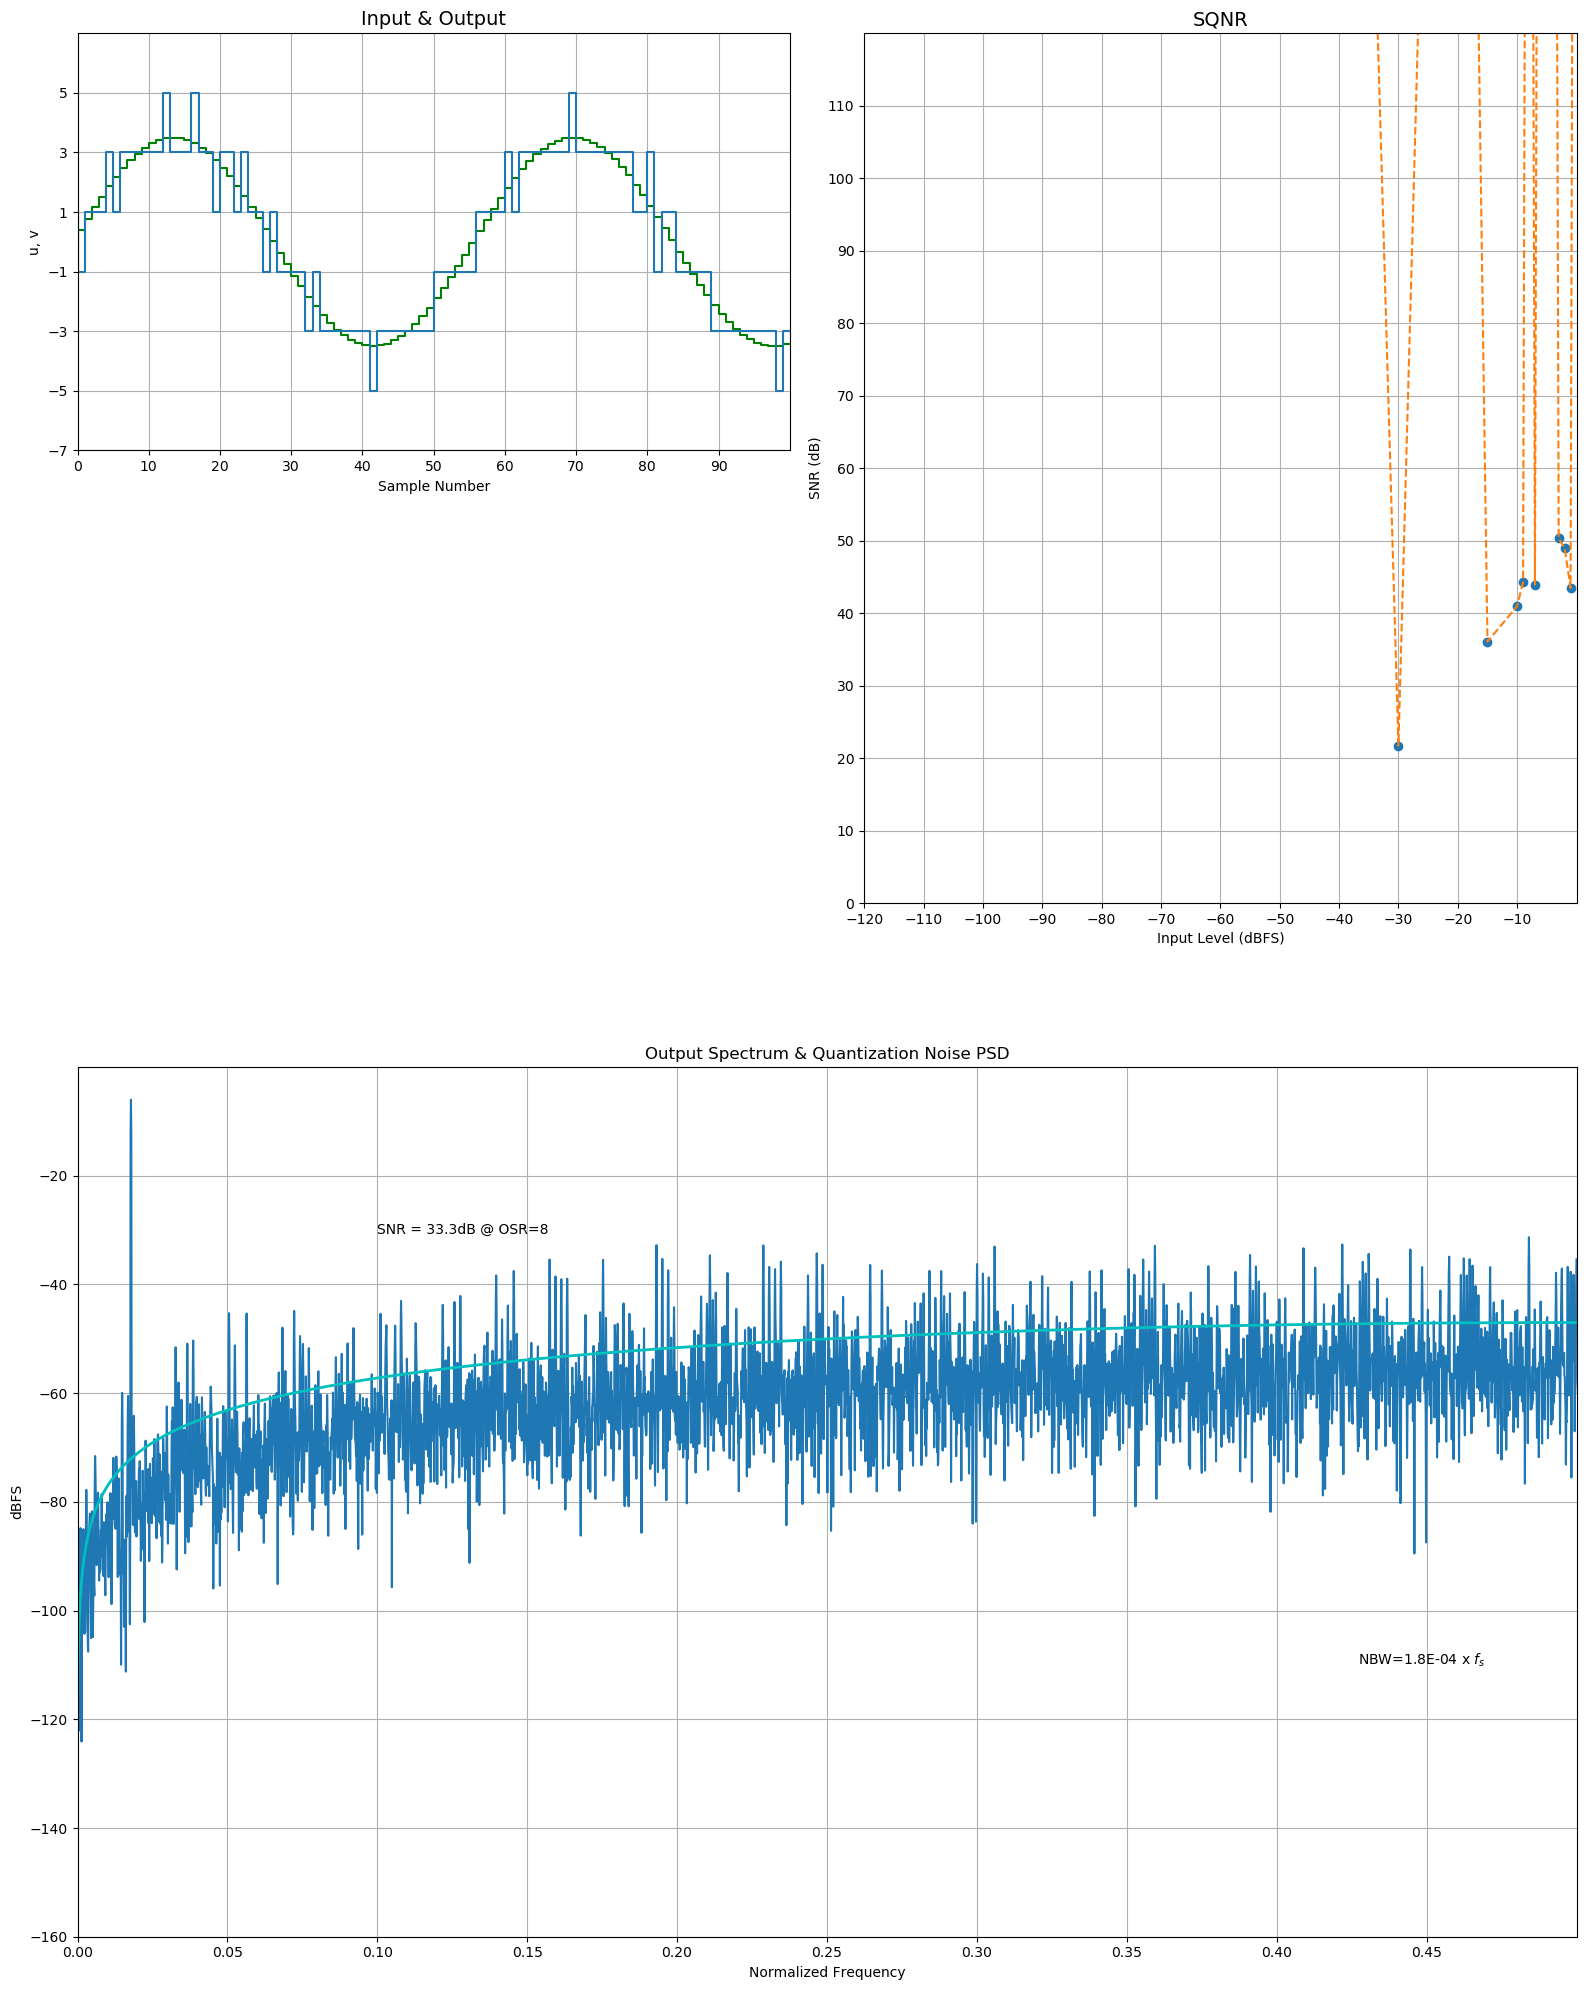

In [9]:
plt.figure(figsize=(16, 20))
M = nlev-1


H = synthesizeNTF(order, osr, 1, Hinf)
N = 8192
fB = int(np.ceil(N/(2.*osr)))
ftest = int(np.floor(2./7*fB))
u = 0.5*M*np.sin(2*np.pi*ftest/N*np.arange(N))
v, xn, xmax, y = simulateDSM(u, H, M + 1)

plt.subplot(int('421'))
t = np.arange(101)
plt.step(t, u[t], 'g')
plt.hold(True)
plt.step(t, v[t])
figureMagic([0, 100], 10, None, [-M, M], 2, None, None,'Input & Output')
plt.xlabel('Sample Number')
plt.ylabel('u, v')

plt.subplot(222)
snr, amp = simulateSNR(H, osr, None, 0., M + 1)
plt.plot(amp, snr,'o', amp, snr, '--')
plt.hold(True)
figureMagic([-120, 0], 10, None, [0, 120], 10, None, None,'SQNR')
plt.xlabel('Input Level (dBFS)')
plt.ylabel('SNR (dB)')

plt.subplot(212)
f = np.linspace(0, 0.5, N//2 + 1)
spec = np.fft.fft(v*ds_hann(N))/(M*N/4)
plt.plot(f, dbv(spec[:N//2 + 1]))
snr = calculateSNR(spec[2:fB + 1], ftest - 2)
plt.text(0.1, 10*(1 - 4), 'SNR = %4.1fdB @ OSR=%d' % (snr, osr), verticalalignment='center')
figureMagic([0, 0.5], 0.05, None, [-160, 0], 20, None, None,'Output Spectrum')
plt.xlabel('Normalized Frequency')
plt.ylabel('dBFS')

NBW = 1.5/N
Sqq = 4*np.abs(evalTF(H, np.exp(2j*np.pi*f)))**2/(3.*M**2)
plt.hold(True)
plt.plot(f, dbp(Sqq*NBW), 'c', linewidth=2)
plt.text(0.47, -110, 'NBW=%4.1E x $f_s$ '% NBW, horizontalalignment='right')
plt.title('Output Spectrum & Quantization Noise PSD')
plt.tight_layout()

/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/scipy/signal/filter_design.py:1628: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  "results may be meaningless", BadCoefficients)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/scipy/signal/filter_design.py:1074: RuntimeWarning: invalid value encountered in true_divide
  b /= b[0]
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_simulateDSM.py:214: UserWarning: Using a slow implementation of simulateDSM
Refer to the docs for how to switch to a fast one
  warn('Using a slow implementation of simulateDSM\n' +
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_PlotExampleSpectrum.py:104: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
  plt.hold(True)
/home/paki/miniconda3/

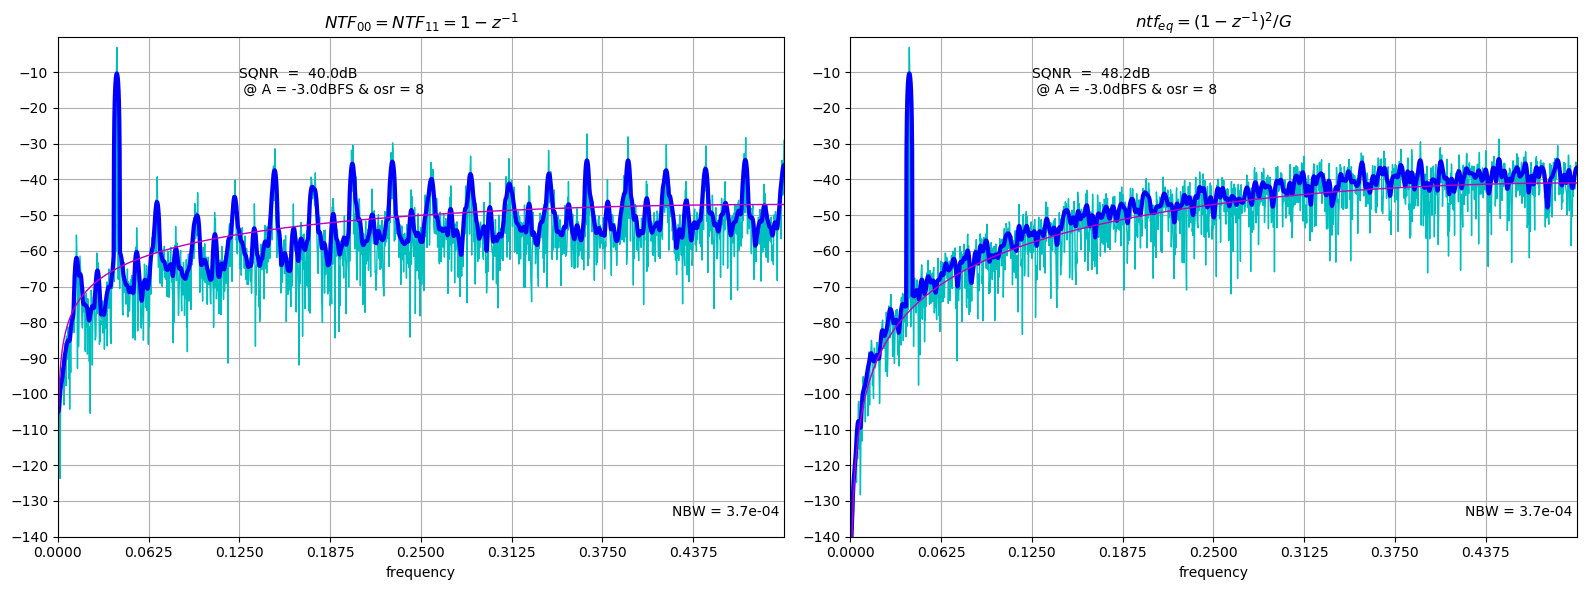

In [5]:
import deltasigma as ds

def zpk_multiply(a, b):
    za, pa, ka = ds._utils._get_zpk(a)
    zb, pb, kb = ds._utils._get_zpk(b)
    pa = pa.tolist() if hasattr(pa, 'tolist') else pa
    pb = pb.tolist() if hasattr(pb, 'tolist') else pb
    za = za.tolist() if hasattr(za, 'tolist') else za
    zb = zb.tolist() if hasattr(zb, 'tolist') else zb
    return ds.cancelPZ((za+zb, pa+pb, ka*kb))

G = 1.0
ABCD_mash = np.array([[1., 0., 1., -1.,  0.],
                      [ G, 1., 0.,  -G, -1.],
                      [1., 0., 0.,  0.,  0.],
                      [0., 1., 0.,  0.,  0.]])

nlev   = [15, 15]
filtM1 = [0., 1.]            # M1 = z⁻¹
filtM2 = [1./G, -1./G]       # M2 = (1 − z⁻¹)/G
k = [1., 1.]
ntfs, stfs = calculateTF(ABCD_mash, k)

M1 = tf2zpk([1.],          [1., 0.])
M2 = tf2zpk([1./G, -1./G], [1., 0.])
ntf_eq = zpk_multiply(ntfs[1, 1], M2)


ponisteno = zpk_multiply(ntfs[0,0], M1), zpk_multiply(ntfs[1,0], M2)   
v1n = zpk_multiply(ntfs[0, 0], M1)
v2n = zpk_multiply(ntfs[1, 0], M2)

plt.figure(figsize=(16, 6))
plt.subplot(121)
PlotExampleSpectrum(ntfs[1, 1], M=7, osr=osr, f0=0)
plt.title('$NTF_{00} = NTF_{11} = 1 - z^{-1}$')
plt.subplot(122)
PlotExampleSpectrum(ntf_eq,     M=7, osr=osr, f0=0)
plt.title('$ntf_{eq} = (1 - z^{-1})^2 / G$')
plt.tight_layout()

In [16]:
print ("NTF_00:\n")
print (pretty_lti(ntfs[0, 0]))
print ("NTF_01:\n")
print (pretty_lti(ntfs[0, 1]))
print ("NTF_10:\n")
print (pretty_lti(ntfs[1, 0]))
print ("NTF_11:\n")
print (pretty_lti(ntfs[1, 1]))


NTF_00:

 (z - 1) 
---------
    z    
NTF_01:

0
NTF_10:

 -4 
----
 z  
NTF_11:

 (z - 1) 
---------
    z    


# Ubrzani testing

/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/scipy/signal/filter_design.py:1628: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  "results may be meaningless", BadCoefficients)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/scipy/signal/filter_design.py:1074: RuntimeWarning: invalid value encountered in true_divide
  b /= b[0]
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/ipykernel_launcher.py:44: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/__init__.py:913: MatplotlibDeprecationWarning: axes.hold is deprecated. Please remove it from your matplotlibrc and/or style files.
  mplDeprecation)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/rcsetup.py:158: M

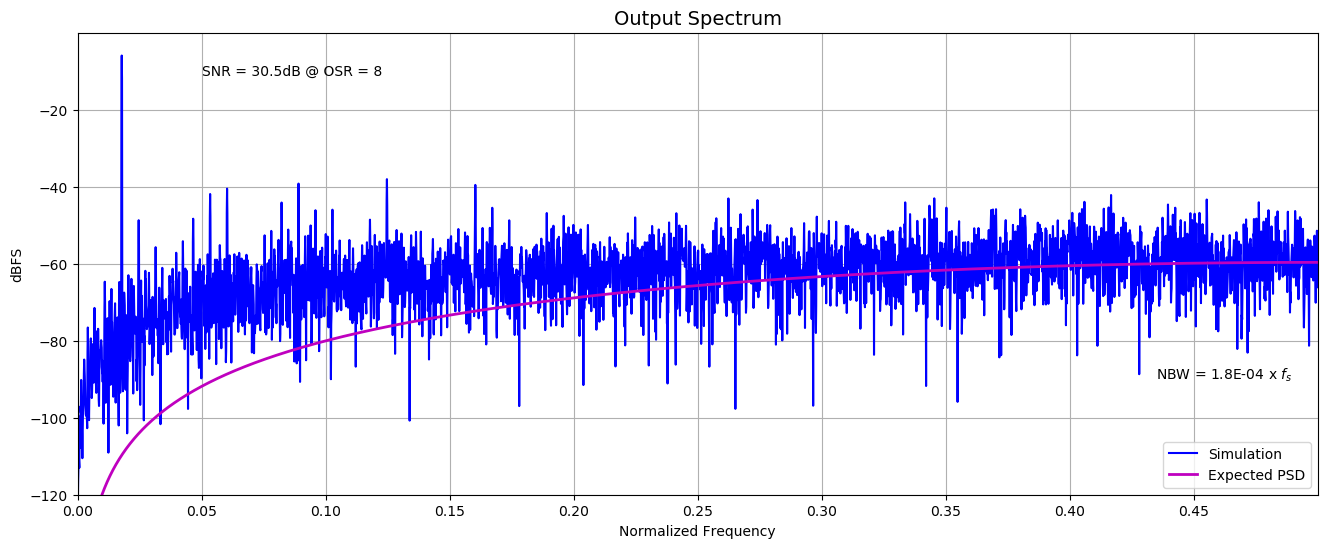

In [23]:
ABCD_mash = np.array([[ 1., 0.,   -1.,  1., 0.],   # x1⁺ = x1 − u + v1
                 [  G, 1.,    0.,  0., 1.],   # x2⁺ = x2 + G·x1 + v2
                 [-1., 0.,    1.,  0., 0.],   # y1  = −x1 + u
                 [ -G,-1.,    0.,  0., 0.]])  # y2  = −G·x1 − x2



G = 4.0                      # medjustepeno pojacanje, stepen dvojke
osr = 8
nlev   = [16, 16]
M = nlev[1] -1
filtM1 = [0., 1.]            # M1 = z⁻¹
filtM2 = [1./G, -1./G]       # M2 = (1 − z⁻¹)/G

k = [1., 1.]
ntfs, stfs = calculateTF(ABCD_mash, k)
M1 = tf2zpk([1.],          [1., 0.])
M2 = tf2zpk([1./G, -1./G], [1., 0.])
ntf_eq = zpk_multiply(ntfs[1, 1], M2)

N = 8192
NBW = 1.5/N
fB = int(np.ceil(N/(2.*osr)))
ftest = np.floor(2./7.*fB)
u = 0.5*M*np.sin(2*np.pi*ftest/N*np.arange(N))

v, xn, xmax, y = simulateDSM(u, ABCD_mash, nlev=[8, 8])
vf = lfilter(filtM1, [1.], v[0]) + lfilter(filtM2, [1.], v[1])




f = np.linspace(0, 0.5, N//2 + 1)
spec = np.fft.fft(vf * ds_hann(N))/(M*N/4)
plt.plot(f, dbv(spec[:N//2 + 1]),'b', label='Simulation')
figureMagic([0, 0.5], 0.05, None, [-120, 0], 20, None, (16, 6), 'Output Spectrum')
plt.xlabel('Normalized Frequency')
plt.ylabel('dBFS')
snr = calculateSNR(spec[2:fB+1], ftest - 2)
plt.text(0.05, -10, 'SNR = %4.1fdB @ OSR = %d' % (snr, osr), verticalalignment='center')

#Sqq = 4*evalTF(ntf_eq, np.exp(2j*np.pi*f)) ** 2/3.
Sqq = 4*np.abs(evalTF(ntf_eq, np.exp(2j*np.pi*f)))**2/3./M**2
plt.hold(True)
plt.plot(f, dbp(Sqq * NBW), 'm', linewidth=2, label='Expected PSD')
plt.text(0.49, -90, 'NBW = %4.1E x $f_s$' % NBW, horizontalalignment='right')
plt.legend(loc=4);